# Model Selection and Clustering

This notebook encapsulates the complete pipeline for selecting the large language models (LLMs) to be subjected to study.

The process consists of:
1. **Data Collection**: Fetching model details from predefined Hugging Face collections.
2. **Filtering**: Applying a set of rules to ignore specialized, quantized, reasoning/thinking, and MoE models.
3. **Prioritization**: Choosing instruction-tuned models over their base versions.
4. **Clustering**: Grouping models into sizes (Tiny, Small, Standard, Mid-range) using Jenks Natural Breaks.
5. **Selection**: Selecting the most recent or largest parameter model available within each category for each family.

### Setup & Imports
We import necessary libraries to handle API requests (`huggingface_hub`), data manipulation (`pandas`), and clustering (`jenkspy`).

In [18]:
import pandas as pd
import jenkspy
import re
import os
import json
from huggingface_hub import HfApi, get_collection, hf_hub_download
from transformers import AutoTokenizer, AutoConfig
from datetime import timedelta

### 1. Configuration and Filtering Rules
Here we define our constants and parameters for model collection. We set maximum limits, regex patterns to extract parameter sizes, and lists of keywords/types to ignore (e.g., GGUF, MoE, Vision models) ensuring we only capture standard text generation base or instruct models.

In [38]:
# Maximum parameter count in billions
MAX_PARAMS = 100

# Path to cache manual entries
MANUAL_CACHE_FILE = "manual_model_data.json"

def load_manual_cache():
    if os.path.exists(MANUAL_CACHE_FILE):
        with open(MANUAL_CACHE_FILE, "r") as f:
            return json.load(f)
    return {}

def save_manual_cache(cache):
    with open(MANUAL_CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=4)

# Load existing cache
MANUAL_CACHE = load_manual_cache()

# Regex Patterns
PARAM_PATTERN = re.compile(r'(\d+(?:\.\d+)?)\s*[Bb]', re.IGNORECASE)
M_PARAM_PATTERN = re.compile(r'(\d+(?:\.\d+)?)\s*m', re.IGNORECASE)

# Matches patterns like 30B-A3B (MoE architecture)
MOE_A_PATTERN = re.compile(r'(\d+(?:\.\d+)?)B-A(\d+(?:\.\d+)?)B', re.IGNORECASE)
# Matches patterns like 17B-128E (LLaMA 4 MoE architecture)
MOE_A_LLAMA_PATTERN = re.compile(r'(\d+(?:\.\d+)?)B-(\d+(?:\.\d+)?)E', re.IGNORECASE)
# Specifically for models that only list activated parameters (e.g. -A2.7B)
MOE_A_ONLY_PATTERN = re.compile(r'-A(\d+(?:\.\d+)?)[B|E]', re.IGNORECASE)
# Specifically for Gemma 4 Per-Layer Embeddings (e.g. -E4B)
GEMMA_E_PATTERN = re.compile(r'-E(\d+(?:\.\d+)?)[B|b]', re.IGNORECASE)
GENERIC_MOE_PATTERN = re.compile(r'moe', re.IGNORECASE)

# Instruction Suffixes
PRIORITIZE_SUFFIXES = ["-it", "-instruct", "-chat", "-instruction", "-hf"]

# Types to ignore
IGNORE_TYPES = {
    "audio-to-audio",
    "text-to-audio",
    "audio-text-to-audio",
    "text-to-image",
    "image-to-image",
    "image-text-to-image"
}

# Specific words to ignore in model names (case-insensitive)
IGNORE_WORDS = {
    # Quantized versions
    "gguf", "awq", "gptq", "quant", "quantized", "int4", "int8", "fp8", "4bit", "6bit", "8bit",
    # Specialized versions
    "special", "speciale", "vision", "image", "audio", "code", "coder", "math", "ocr", "guard",
    "pytorch", "keras", "flax", "cpp", "tflite", "mlx", "terminus", "exp", "shield", "assistant",
    # Not instruction-tuned versions
    "base", "-pt",
    # Others
    "deprecated"
}

# Specific models to ignore by exact model ID
IGNORE_MODELS = {
    # Hugging Face base models that are not instruction-tuned, confusing the prioritization logic.
    "meta-llama/Llama-2-7b-hf",
    "meta-llama/Llama-2-13b-hf",
    # gemma-4-31B Ignored due to "repetition collapse",
    # bug that is not fixed as of April 2026.
    "google/gemma-4-31B",
    "google/gemma-4-31B-it",
}

# Specific models to explicitly identify as MoE
MOE_MODELS = {
    "deepseek-ai/DeepSeek-V2",
    "deepseek-ai/DeepSeek-V2-Chat", 
    "deepseek-ai/DeepSeek-V2-Lite-Chat",
    "deepseek-ai/DeepSeek-V2.5",
    "deepseek-ai/DeepSeek-V2.5-1210",
    "deepseek-ai/DeepSeek-V3",
    "deepseek-ai/DeepSeek-V3-Base",
    "DeepSeek-V3.1-Base",
    "DeepSeek-V3.1",
    "DeepSeek-V3.2",
}

# Specific models to explicitly identify as Thinking/Reasoning
THINKING_MODELS = {"deepseek-ai/DeepSeek-R1-0528-Qwen3-8B"}

# Specific words to identify as Thinking/Reasoning (case-insensitive)
THINKING_WORDS = {"reason", "reasoning", "think", "thinking"}

### 2. Helper Functions
These functions parse model names to extract parameter sizes and query the Hugging Face API (`get_model_details`). During the API query, the model is checked against the ignoring rules before being accepted.

In [39]:
def format_to_billions(num):
    """Converts raw integer or float to 'X.XX' string."""
    if num is None or num == "N/A":
        return "N/A"
    try:
        return f"{float(num) / 1e9:.2f}"
    except (ValueError, TypeError):
        return str(num)

def prompt_for_missing_value(model_id, field_name):
    """Prompts the user to manually input a missing value for a model and caches it."""
    # Check cache first
    cache_key = f"{model_id}|{field_name}"
    if cache_key in MANUAL_CACHE:
        return MANUAL_CACHE[cache_key]
        
    while True:
        user_input = input(f"Enter {field_name} (in billions, e.g., 7.0) for {model_id}: ").strip()
        if not user_input:
            print("Value is required. Please enter a number.")
            continue
        try:
            val = f"{float(user_input):.2f}"
            # Update cache and save
            MANUAL_CACHE[cache_key] = val
            save_manual_cache(MANUAL_CACHE)
            return val
        except ValueError:
            print("Invalid input. Please enter a numeric value.")

def extract_params_from_name(model_id):
    """
    Tries to find parameter count and density details in the model name.
    Returns (discovered_total, discovered_active, is_moe)
    """
    model_name_only = model_id.split('/')[-1]
    
    # 1. Check for explicit MoE Total and Active (e.g., 14B-A2.7B)
    moe_a_match = MOE_A_PATTERN.search(model_name_only)
    if moe_a_match:
        total = f"{float(moe_a_match.group(1)):.2f}"
        active = f"{float(moe_a_match.group(2)):.2f}"
        return total, active, True

    # 1b. Check for LLaMA 4 MoE pattern (e.g., 17B-128E)
    moe_a_llama_match = MOE_A_LLAMA_PATTERN.search(model_name_only)
    if moe_a_llama_match:
        active = f"{float(moe_a_llama_match.group(1)):.2f}"
        return "N/A", active, True

    # 2. Check for Active only pattern (e.g., -A2.7B)
    moe_a_only_match = MOE_A_ONLY_PATTERN.search(model_name_only)
    if moe_a_only_match:
        active = f"{float(moe_a_only_match.group(1)):.2f}"
        return "N/A", active, True
    
    # 3. Check for Gemma 4 'E' pattern (e.g., -E4B)
    gemma_e_match = GEMMA_E_PATTERN.search(model_name_only)
    if gemma_e_match:
        active = f"{float(gemma_e_match.group(1)):.2f}"
        # For Gemma 'E' models, total is often not specified in name
        return "N/A", active, True

    # 4. Fallback to generic parameter extraction
    is_moe = bool(GENERIC_MOE_PATTERN.search(model_name_only))
    
    match = PARAM_PATTERN.search(model_name_only)
    if match:
        try:
            val = f"{float(match.group(1)):.2f}"
            return val, val, is_moe
        except ValueError:
            pass
    else:
        alt_match = M_PARAM_PATTERN.search(model_name_only)
        if alt_match:
            try:
                val = f"{(float(alt_match.group(1))/1000):.2f}"
                return val, val, is_moe
            except ValueError:
                pass
                
    return "N/A", "N/A", is_moe

def check_is_thinking(model_id):
    """
    Checks if a model is a reasoning/thinking model based on:
    0. Hardcoded NON_THINKING_MODELS list (overrides all)
    1. Hardcoded THINKING_MODELS list
    2. Name containing thinking words
    3. Chat template containing thinking tags
    """
    if model_id in THINKING_MODELS:
        return True
        
    model_id_lower = model_id.lower()
    if any(word in model_id_lower for word in THINKING_WORDS):
        return True
    
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        # Check for the presence of 'think' tags in the default chat template
        if tokenizer.chat_template:
            template = tokenizer.chat_template
            if isinstance(template, list):
                template = str(template)
            thinking_tags = ["<think>", "<reasoning>", "<|think|>", "<|channel>thought"]
            if any(tag in template for tag in thinking_tags):
                return True
    except Exception:
        pass
        
    return False

def get_max_model_length(model_id):
    """
    Attempts to fetch the maximum natively supported context length from the model's config.
    """
    try:
        config = AutoConfig.from_pretrained(model_id, trust_remote_code=True)
        
        # Some multimodal models (like Gemma 3) store their text sequence length inside a text_config
        target_config = config.text_config if hasattr(config, "text_config") else config
        
        # Check standard config attributes used by different architectures for max context length
        if hasattr(target_config, "max_position_embeddings"):
            return target_config.max_position_embeddings
        elif hasattr(target_config, "n_positions"):
            return target_config.n_positions
        elif hasattr(target_config, "seq_length"):
            return target_config.seq_length
        elif hasattr(target_config, "max_sequence_length"):
            return target_config.max_sequence_length
            
    except Exception:
        pass
        
    return "N/A"

def get_total_parameters_from_config(model_id):
    """
    Attempts to calculate the total number of parameters accurately by instantiating an 
    empty model from the config and extracting the parameter count directly.
    """
    try:
        from transformers import AutoModelForCausalLM
        import accelerate
        
        config = AutoConfig.from_pretrained(model_id, trust_remote_code=True)
        # Initialize an empty model using accelerate to avoid downloading weights
        with accelerate.init_empty_weights():
            model = AutoModelForCausalLM.from_config(config, trust_remote_code=True)
            
        return format_to_billions(model.num_parameters())
    except Exception:
        return "N/A"

def get_model_details(api, model_id):
    """Fetches details and returns (model_dict, status_string)."""
    try:
        # 1. Filter out by model id if it's in the ignore list
        if model_id in IGNORE_MODELS:
            return None, "Manually ignored"

        # 2. Filter out by ignored words in the name
        model_id_lower = model_id.lower()
        for word in IGNORE_WORDS:
            if word.lower() in model_id_lower:
                return None, f"Ignored word '{word}'"

        # Fetch model info only after local name checks pass
        info = api.model_info(model_id)

        # 3. Filter out ignored model types
        if info.pipeline_tag and info.pipeline_tag.lower() in IGNORE_TYPES:
            return None, f"Ignored type '{info.pipeline_tag}'"

        if info.tags:
            for tag in info.tags:
                if tag.lower() in IGNORE_TYPES:
                    return None, f"Ignored tag '{tag}'"

        # 4. Extract Release Date
        release_date = info.created_at.strftime("%Y-%m-%d") if info.created_at else "N/A"

        # 5. Extract Parameter Counts (Metadata -> Config -> Name Fallback -> Manual Prompt)
        total_params = "N/A"
        activated_params = "N/A"
        is_moe = False
        
        # A. Check safetensors metadata first for total params (Source of Truth)
        if info.safetensors and "total" in info.safetensors:
            total_params = format_to_billions(info.safetensors["total"])
            
        # B. Check config for total params
        if total_params == "N/A":
            # Attempt to use AutoConfig and empty model trick
            total_params = get_total_parameters_from_config(model_id)
            
        # C. Discover counts from name as fallback
        n_total, n_active, n_is_moe = extract_params_from_name(model_id)
        
        # D. Identification logic
        is_moe = n_is_moe
        if info.tags and any("moe" in tag.lower() for tag in info.tags):
            is_moe = True
        if model_id in MOE_MODELS:
            is_moe = True
            
        # E. Parameters Assignment logic
        # If metadata and config are both missing total, use name's total
        if total_params == "N/A":
            total_params = n_total
        
        # If still N/A, prompt manually
        if total_params == "N/A":
            total_params = prompt_for_missing_value(model_id, "Total Parameters")
        
        if is_moe:
            # For MoE, use 'active' from name if found, else fallback to N/A
            activated_params = n_active if n_active != "N/A" else "N/A"
            if activated_params == "N/A":
                # Only prompt if it's definitely MoE and we don't have active params
                activated_params = prompt_for_missing_value(model_id, "Activated Parameters")
        else:
            # For dense, both are the same
            activated_params = total_params

        if total_params != "N/A" and float(total_params) > MAX_PARAMS:
            return None, f"Exceeds max params ({total_params}B > {MAX_PARAMS}B)"
            
        # 6. Determine Thinking Mode
        is_thinking = check_is_thinking(model_id)

        # 7. Extract Max Context Length
        max_model_length = get_max_model_length(model_id)

        return {
            "model": model_id,
            "total_parameters": total_params,
            "activated_parameters": activated_params,
            "max_model_length": max_model_length,
            "is_moe": is_moe,
            "is_thinking": is_thinking,
            "release_date": release_date
        }, "Accepted"
    except Exception as e:
        return None, f"API Error: {e}"

### 3. Fetching Data from Hugging Face
We iterate over the list of chosen collections, fetch the models in each collection, and apply our filtering logic to compile a list of viable models.

In [40]:
COLLECTIONS = [
    # Original Qwen collection is ignored since its models are not natively supported by Hugging Face Transformers,
    # needing to run remote code that fails since it is not compatible with current package versions.
    # The Qwen 1.5 collection contains re-released model weights from the original Qwen collection,
    # but in a format that is natively supported.
    "Qwen/qwen15",
    "Qwen/qwen2",
    "Qwen/qwen25",
    "Qwen/qwen3",
    "Qwen/qwen35",
    "Qwen/qwen36",
    "meta-llama/llama-2-family",
    "meta-llama/meta-llama-3",
    "meta-llama/llama-31",
    "meta-llama/llama-32",
    "meta-llama/llama-33",
    "meta-llama/llama-4",
    "deepseek-ai/deepseek-llm",
    "deepseek-ai/deepseek-v2",
    "deepseek-ai/deepseek-v25",
    "deepseek-ai/deepseek-r1",
    "deepseek-ai/deepseek-v3",
    "deepseek-ai/deepseek-v31",
    "deepseek-ai/deepseek-v32",
    "deepseek-ai/deepseek-v4",
    "google/gemma-release",
    "google/gemma-2-release",
    "google/gemma-3-release",
    "google/gemma-3n",
    "google/gemma-4",
    "mistralai/ministral-3"
]

api = HfApi()
rows = []

for col_id in COLLECTIONS:
    print(f"\n📦 Collection: {col_id}")
    try:
        collection = get_collection(col_id)
        for item in collection.items:
            if item.item_type == "model":
                details, reason = get_model_details(api, item.item_id)
                
                if details:
                    details["collection"] = col_id
                    details["collection_name"] = collection.title
                    rows.append(details)
                    print(f"  ✓ {item.item_id}")
                else:
                    print(f"  ✗ {item.item_id} (Reason: {reason})")
    except Exception as e:
        print(f"  [!] Collection Error: {e}")



📦 Collection: Qwen/qwen15
  ✗ Qwen/Qwen1.5-110B-Chat (Reason: Exceeds max params (111.21B > 100B))
  ✗ Qwen/Qwen1.5-110B (Reason: Exceeds max params (111.21B > 100B))
  ✓ Qwen/Qwen1.5-32B
  ✓ Qwen/Qwen1.5-32B-Chat
  ✓ Qwen/Qwen1.5-72B-Chat
  ✓ Qwen/Qwen1.5-72B
  ✓ Qwen/Qwen1.5-MoE-A2.7B
  ✓ Qwen/Qwen1.5-MoE-A2.7B-Chat
  ✓ Qwen/Qwen1.5-4B
  ✓ Qwen/Qwen1.5-4B-Chat
  ✗ Qwen/Qwen1.5-32B-Chat-GPTQ-Int4 (Reason: Ignored word 'int4')
  ✗ Qwen/Qwen1.5-32B-Chat-GGUF (Reason: Ignored word 'gguf')
  ✗ Qwen/Qwen1.5-32B-Chat-AWQ (Reason: Ignored word 'awq')
  ✓ Qwen/Qwen1.5-0.5B
  ✓ Qwen/Qwen1.5-0.5B-Chat
  ✓ Qwen/Qwen1.5-1.8B
  ✓ Qwen/Qwen1.5-7B
  ✓ Qwen/Qwen1.5-14B
  ✓ Qwen/Qwen1.5-14B-Chat
  ✗ Qwen/Qwen1.5-0.5B-Chat-GPTQ-Int4 (Reason: Ignored word 'int4')
  ✗ Qwen/Qwen1.5-7B-Chat-GPTQ-Int4 (Reason: Ignored word 'int4')
  ✓ Qwen/Qwen1.5-1.8B-Chat
  ✓ Qwen/Qwen1.5-7B-Chat
  ✗ Qwen/Qwen1.5-0.5B-Chat-GPTQ-Int8 (Reason: Ignored word 'int8')
  ✗ Qwen/Qwen1.5-14B-Chat-GPTQ-Int4 (Reason: Ignored word '

[transformers] `rope_parameters`'s high_freq_factor field must be greater than low_freq_factor, got high_freq_factor=1.0 and low_freq_factor=1.0


  ✗ meta-llama/Llama-4-Scout-17B-16E-Instruct (Reason: Exceeds max params (109.00B > 100B))


[transformers] `rope_parameters`'s high_freq_factor field must be greater than low_freq_factor, got high_freq_factor=1.0 and low_freq_factor=1.0


  ✗ meta-llama/Llama-4-Scout-17B-16E (Reason: Exceeds max params (109.00B > 100B))
  ✗ meta-llama/Llama-4-Maverick-17B-128E-Instruct (Reason: Exceeds max params (401.58B > 100B))
  ✗ meta-llama/Llama-4-Maverick-17B-128E-Instruct-FP8 (Reason: Ignored word 'fp8')
  ✗ meta-llama/Llama-4-Maverick-17B-128E (Reason: Exceeds max params (401.58B > 100B))
  ✗ meta-llama/Llama-4-Scout-17B-16E-Instruct-Original (Reason: Exceeds max params (109.00B > 100B))
  ✗ meta-llama/Llama-4-Maverick-17B-128E-Instruct-FP8-Original (Reason: Ignored word 'fp8')
  ✗ meta-llama/Llama-4-Scout-17B-16E-Original (Reason: Exceeds max params (109.00B > 100B))
  ✗ meta-llama/Llama-4-Maverick-17B-128E-Instruct-Original (Reason: Exceeds max params (400.00B > 100B))
  ✗ meta-llama/Llama-4-Maverick-17B-128E-Original (Reason: Exceeds max params (400.00B > 100B))
  ✗ meta-llama/Llama-Prompt-Guard-2-22M (Reason: Ignored word 'guard')
  ✗ meta-llama/Llama-Prompt-Guard-2-86M (Reason: Ignored word 'guard')
  ✗ meta-llama/Llama-Gu

...

  ✓ mistralai/Ministral-3-14B-Instruct-2512


[transformers] The tokenizer you are loading from 'mistralai/Ministral-3-8B-Instruct-2512' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


  ✓ mistralai/Ministral-3-8B-Instruct-2512


[transformers] The tokenizer you are loading from 'mistralai/Ministral-3-3B-Instruct-2512' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


  ✓ mistralai/Ministral-3-3B-Instruct-2512
  ✓ mistralai/Ministral-3-14B-Reasoning-2512
  ✓ mistralai/Ministral-3-8B-Reasoning-2512
  ✓ mistralai/Ministral-3-3B-Reasoning-2512
  ✗ mistralai/Ministral-3-14B-Base-2512 (Reason: Ignored word 'base')
  ✗ mistralai/Ministral-3-8B-Base-2512 (Reason: Ignored word 'base')
  ✗ mistralai/Ministral-3-3B-Base-2512 (Reason: Ignored word 'base')


### 4. Post-Processing: Prioritize Instruction-Tuned Models
If a base model and its instruction-tuned variant (e.g., `-it`, `-chat`) both exist in the parsed list, we remove the base model and keep only the instruction-tuned version.

In [41]:
model_map = {r["model"]: r for r in rows}
to_remove = {}

for model_id in model_map.keys():
    for s in PRIORITIZE_SUFFIXES:
        s_lower = s.lower()
        model_id_lower = model_id.lower()
        if model_id_lower.endswith(s_lower):
            base_name = model_id[:-len(s)]
            if base_name in model_map:
                to_remove[base_name] = model_id

print("\n🔄 Prioritizing Models:")
if not to_remove:
    print("  - No base models needed removal.")
else:
    for base, tuned in to_remove.items():
        print(f"  ✗ Removed {base}")
        print(f"  ↳ ✓ Kept {tuned}")

final_rows = [r for r in rows if r["model"] not in to_remove]



🔄 Prioritizing Models:
  ✗ Removed Qwen/Qwen1.5-32B
  ↳ ✓ Kept Qwen/Qwen1.5-32B-Chat
  ✗ Removed Qwen/Qwen1.5-72B
  ↳ ✓ Kept Qwen/Qwen1.5-72B-Chat
  ✗ Removed Qwen/Qwen1.5-MoE-A2.7B
  ↳ ✓ Kept Qwen/Qwen1.5-MoE-A2.7B-Chat
  ✗ Removed Qwen/Qwen1.5-4B
  ↳ ✓ Kept Qwen/Qwen1.5-4B-Chat
  ✗ Removed Qwen/Qwen1.5-0.5B
  ↳ ✓ Kept Qwen/Qwen1.5-0.5B-Chat
  ✗ Removed Qwen/Qwen1.5-14B
  ↳ ✓ Kept Qwen/Qwen1.5-14B-Chat
  ✗ Removed Qwen/Qwen1.5-1.8B
  ↳ ✓ Kept Qwen/Qwen1.5-1.8B-Chat
  ✗ Removed Qwen/Qwen1.5-7B
  ↳ ✓ Kept Qwen/Qwen1.5-7B-Chat
  ✗ Removed Qwen/Qwen2-72B
  ↳ ✓ Kept Qwen/Qwen2-72B-Instruct
  ✗ Removed Qwen/Qwen2-7B
  ↳ ✓ Kept Qwen/Qwen2-7B-Instruct
  ✗ Removed Qwen/Qwen2-57B-A14B
  ↳ ✓ Kept Qwen/Qwen2-57B-A14B-Instruct
  ✗ Removed Qwen/Qwen2-1.5B
  ↳ ✓ Kept Qwen/Qwen2-1.5B-Instruct
  ✗ Removed Qwen/Qwen2-0.5B
  ↳ ✓ Kept Qwen/Qwen2-0.5B-Instruct
  ✗ Removed Qwen/Qwen2.5-0.5B
  ↳ ✓ Kept Qwen/Qwen2.5-0.5B-Instruct
  ✗ Removed Qwen/Qwen2.5-1.5B
  ↳ ✓ Kept Qwen/Qwen2.5-1.5B-Instruct
  ✗ Remove

### 5. Build DataFrame
We ingest our final collected row definitions into a structured Pandas DataFrame to facilitate easier data processing.

In [102]:
df = pd.DataFrame(final_rows)
df['total_parameters'] = pd.to_numeric(df['total_parameters'], errors='coerce')
df = df.dropna(subset=['total_parameters']).copy()
df.to_csv("models.csv", index=False)

### 6. Calculate Natural Breaks with Jenks
To properly categorize models into distinct size categories without arbitrary thresholds, we use Jenks Natural Breaks optimization. This seeks to minimize each class's average deviation from the class mean, while maximizing each class's deviation from the means of the other groups.

In [4]:
df = pd.read_csv("models.csv")
column_data = df['total_parameters']
values = column_data.dropna().astype(float).to_list()
breaks = jenkspy.jenks_breaks(values, n_classes=5)
breaks

[np.float64(0.44),
 np.float64(5.12),
 np.float64(9.65),
 np.float64(15.71),
 np.float64(35.95),
 np.float64(72.71)]

### 7. Assign Labels
Apply the calculated bins to split our dataframe into 'Tiny/Mobile', 'Small/Edge', 'Standard/Desktop', 'Mid-range/Server' and 'Large/Enterprise' tiers.

In [5]:
# Define categories based on breaks
df["category"] = pd.cut(
    column_data,
    bins=breaks,
    labels=[
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
        "Mid-range/Server",
        "Large/Enterprise",
    ],
    ordered=False,
    include_lowest=True,
)

# Define order of columns
df = df[
    [
        "collection",
        "collection_name",
        "model",
        "total_parameters",
        "activated_parameters",
        "max_model_length",
        "is_moe",
        "is_thinking",
        "release_date",
        "category",
    ]
]

print("Total models after categorization:", len(df))

Total models after categorization: 83


#### Visualization of model distribution over time by size category

Across all five size categories, there is a consistent presence of both older and newly released models (late 2023 to early 2026).

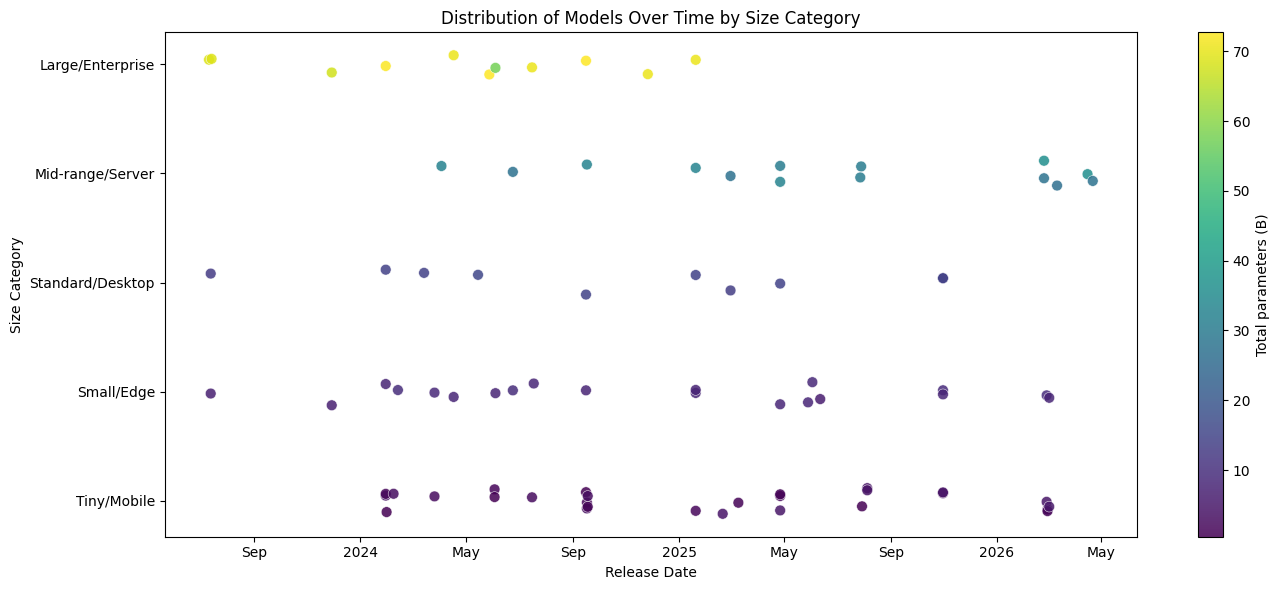

In [6]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Prepare dataframe
plot_df = df.copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

# Ensure consistent category ordering
cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop", "Mid-range/Server", "Large/Enterprise"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

# Map categories to numeric positions and add jitter for visibility
y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

# Scatter plot (x=release date, y=category), color = total parameters
fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap="viridis",
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category")

# Nicely format dates on x-axis
locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
plt.show()

### 8. Filter Out Size Categories

Keep only models whose size category is compatible with local hardware limits. For this study, an NVIDIA L40S GPU with ~45GB or VRAM is used, which can handle loading models of up to 20B total parameters in full BF16 precision. This limits our study to the size categories bellow Mid-range/Server.

In [7]:
df = df[~df["category"].isin(["Mid-range/Server", "Large/Enterprise"])].copy()
print("Remaining models:", len(df))

Remaining models: 58


### 8. Filter Selection per Family & Size Category

To refine the experimental selection, we apply the following rules within each combination of **size category**, **model family (collection)**, **architecture type (Dense vs. MoE)** and **thinking mode**:

1. **Size Priority**: If multiple models exist, select the one with the largest parameter count.
2. **Recency Priority**: If there is a tie in parameter count, select the most recently released model.

The resulting dataset is then saved to a CSV file.

In [8]:
df["total_parameters"] = pd.to_numeric(df["total_parameters"], errors="coerce")
df["activated_parameters"] = pd.to_numeric(df["activated_parameters"], errors="coerce")
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

filtered_df = (
    df.sort_values(
        by=["category", "collection", "total_parameters", "release_date"],
        ascending=[True, True, False, False],
    )
    .drop_duplicates(
        subset=["category", "collection", "is_moe", "is_thinking"], keep="first"
    )
    .copy()
)

filtered_df.sort_values(
    by=["category", "release_date"], ascending=[True, True], inplace=True
)
filtered_df.reset_index(drop=True, inplace=True)

filtered_df.to_csv("selected_models.csv", index=False)

print("Remaining models after filtering and prioritization:", len(filtered_df))

Remaining models after filtering and prioritization: 40


### 9. Final Statistics
Displaying the number of models successfully selected per category.

In [9]:
filtered_df.groupby("category").size().reindex(
    [
        "Tiny/Mobile",
        "Small/Edge",
        "Standard/Desktop",
        "Mid-range/Server",
        "Large/Enterprise",
    ]
)

category
Tiny/Mobile         14.0
Small/Edge          16.0
Standard/Desktop    10.0
Mid-range/Server     NaN
Large/Enterprise     NaN
dtype: float64

#### Visualization of model distribution over time by size category, after filtering.

The presence of both older and newer models across all categories is not affected by the selection process.

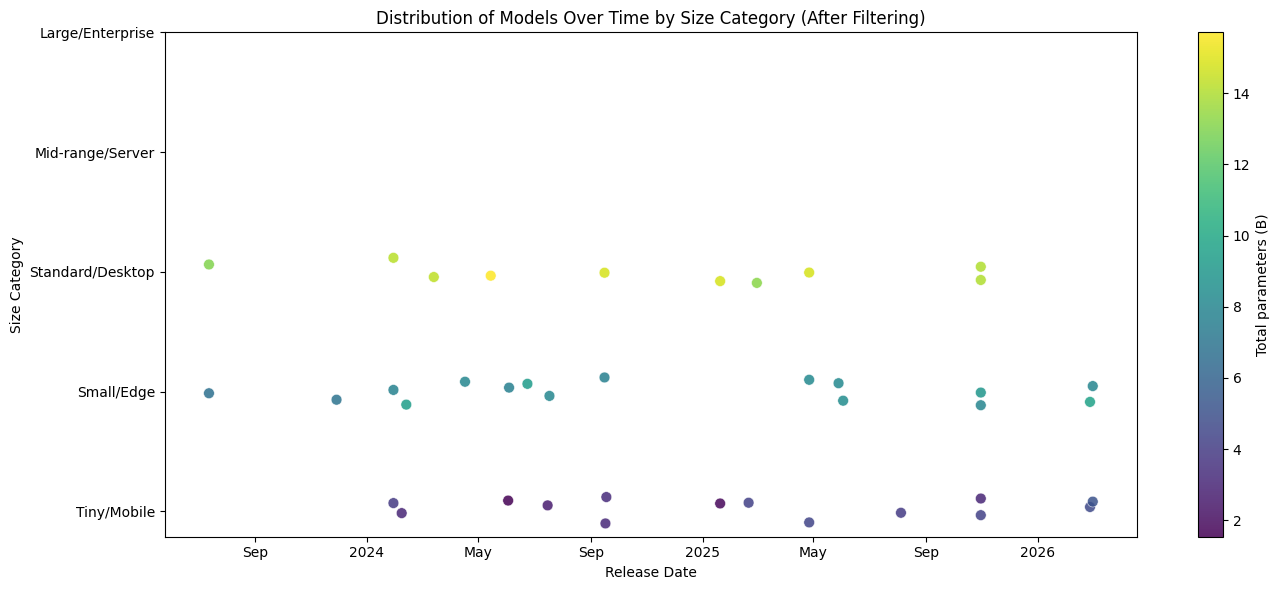

In [10]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Prepare dataframe
plot_df = filtered_df.copy()
plot_df["release_date"] = pd.to_datetime(plot_df["release_date"], errors="coerce")
plot_df = plot_df.dropna(subset=["release_date", "category"]).copy()

# Ensure consistent category ordering
cat_order = ["Tiny/Mobile", "Small/Edge", "Standard/Desktop", "Mid-range/Server", "Large/Enterprise"]
plot_df["category"] = pd.Categorical(plot_df["category"], categories=cat_order, ordered=True)
plot_df = plot_df.dropna(subset=["category"])

# Map categories to numeric positions and add jitter for visibility
y_codes = plot_df["category"].cat.codes.to_numpy()
rng = np.random.default_rng(42)
jitter = (rng.random(len(y_codes)) - 0.5) * 0.25
y_jitter = y_codes + jitter

# Scatter plot (x=release date, y=category), color = total parameters
fig, ax = plt.subplots(figsize=(14, 6))
sc = ax.scatter(
    plot_df["release_date"],
    y_jitter,
    c=plot_df["total_parameters"],
    cmap="viridis",
    s=60,
    alpha=0.85,
    edgecolors="w",
    linewidth=0.4,
)

ax.set_yticks(range(len(cat_order)))
ax.set_yticklabels(cat_order)
ax.set_xlabel("Release Date")
ax.set_ylabel("Size Category")
ax.set_title("Distribution of Models Over Time by Size Category (After Filtering)")

# Nicely format dates on x-axis
locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total parameters (B)")

plt.tight_layout()
plt.show()

### 10. Select a Representative Model for each Category
These models will be used to approximate the total runtime of the final experiment.

In [11]:
thinking = ~filtered_df['is_moe'] & filtered_df['is_thinking']
thinking_models = filtered_df[thinking].loc[
    filtered_df[thinking].groupby('category')['total_parameters'].idxmax()
]

instruct = ~filtered_df['is_moe'] & ~filtered_df['is_thinking']
instruct_models = filtered_df[instruct].loc[
    filtered_df[instruct].groupby('category')['total_parameters'].idxmax()
]

moe_thinking = filtered_df['is_moe'] & filtered_df['is_thinking']
moe_thinking_models = filtered_df[moe_thinking].loc[
    filtered_df[moe_thinking].groupby('category')['total_parameters'].idxmax()
]

moe_instruct = filtered_df['is_moe'] & ~filtered_df['is_thinking']
moe_instruct_models = filtered_df[moe_instruct].loc[
    filtered_df[moe_instruct].groupby('category')['total_parameters'].idxmax()
]

representative_models = pd.concat(
    [
        thinking_models,
        instruct_models,
        moe_thinking_models,
        moe_instruct_models,
    ]
).drop_duplicates()

representative_models.to_csv('representative_models.csv', index=False)
representative_models

,collection,collection_name,model,total_parameters,activated_parameters,max_model_length,is_moe,is_thinking,release_date,category
12,Qwen/qwen35,Qwen3.5,Qwen/Qwen3.5-4B,4.66,4.66,262144.0,False,True,2026-02-27,Tiny/Mobile
28,Qwen/qwen35,Qwen3.5,Qwen/Qwen3.5-9B,9.65,9.65,262144.0,False,True,2026-02-27,Small/Edge
35,deepseek-ai/deepseek-r1,DeepSeek-R1,deepseek-ai/DeepSeek-R1-Distill-Qwen-14B,14.77,14.77,131072.0,False,True,2025-01-20,Standard/Desktop
7,google/gemma-3-release,Gemma 3 Release,google/gemma-3-4b-it,4.30,4.30,131072.0,False,False,2025-02-20,Tiny/Mobile
17,google/gemma-release,Gemma release,google/gemma-7b-it,9.32,9.32,8192.0,False,False,2024-02-13,Small/Edge
34,Qwen/qwen25,Qwen2.5,Qwen/Qwen2.5-14B-Instruct,14.77,14.77,32768.0,False,False,2024-09-16,Standard/Desktop
13,google/gemma-4,Gemma 4,google/gemma-4-E2B-it,5.12,2.00,131072.0,True,True,2026-03-02,Tiny/Mobile
29,google/gemma-4,Gemma 4,google/gemma-4-E4B-it,8.00,4.00,131072.0,True,True,2026-03-02,Small/Edge
25,google/gemma-3n,Gemma 3n,google/gemma-3n-E4B-it,8.36,4.00,32768.0,True,False,2025-06-03,Small/Edge
33,deepseek-ai/deepseek-v2,DeepSeek-V2,deepseek-ai/DeepSeek-V2-Lite-Chat,15.71,2.40,163840.0,True,False,2024-05-15,Standard/Desktop


### 11. Approximate experiment runtime
The collected runtime metrics will aid in approximating the total experiment runtime.

In [35]:
REPETITIONS = 10
COOLDOWN_BETWEEN_RUNS_SECONDS = 30

nrThinkingTiny = len(filtered_df[thinking].loc[filtered_df[thinking]['category'] == 'Tiny/Mobile'])
nrThinkingSmall = len(filtered_df[thinking].loc[filtered_df[thinking]['category'] == 'Small/Edge'])
nrThinkingStandard = len(filtered_df[thinking].loc[filtered_df[thinking]['category'] == 'Standard/Desktop'])

nrInstructTiny = len(filtered_df[instruct].loc[filtered_df[instruct]['category'] == 'Tiny/Mobile'])
nrInstructSmall = len(filtered_df[instruct].loc[filtered_df[instruct]['category'] == 'Small/Edge'])
nrInstructStandard = len(filtered_df[instruct].loc[filtered_df[instruct]['category'] == 'Standard/Desktop'])

nrMoeThinkingTiny = len(filtered_df[moe_thinking].loc[filtered_df[moe_thinking]['category'] == 'Tiny/Mobile'])
nrMoeThinkingSmall = len(filtered_df[moe_thinking].loc[filtered_df[moe_thinking]['category'] == 'Small/Edge'])
nrMoeThinkingStandard = len(filtered_df[moe_thinking].loc[filtered_df[moe_thinking]['category'] == 'Standard/Desktop'])

nrMoeInstructTiny = len(filtered_df[moe_instruct].loc[filtered_df[moe_instruct]['category'] == 'Tiny/Mobile'])
nrMoeInstructSmall = len(filtered_df[moe_instruct].loc[filtered_df[moe_instruct]['category'] == 'Small/Edge'])
nrMoeInstructStandard = len(filtered_df[moe_instruct].loc[filtered_df[moe_instruct]['category'] == 'Standard/Desktop'])

nrTotalRuns = (
    nrThinkingTiny + nrThinkingSmall + nrThinkingStandard +
    nrInstructTiny + nrInstructSmall + nrInstructStandard +
    nrMoeThinkingTiny + nrMoeThinkingSmall + nrMoeThinkingStandard +
    nrMoeInstructTiny + nrMoeInstructSmall + nrMoeInstructStandard
) * REPETITIONS

print(f"Number of runs for Thinking Tiny/Mobile models: {nrThinkingTiny * REPETITIONS}")
print(f"Number of runs for Thinking Small/Edge models: {nrThinkingSmall * REPETITIONS}")
print(f"Number of runs for Thinking Standard/Desktop models: {nrThinkingStandard * REPETITIONS}")
print(f"Number of runs for Instruct Tiny/Mobile models: {nrInstructTiny * REPETITIONS}")
print(f"Number of runs for Instruct Small/Edge models: {nrInstructSmall * REPETITIONS}")
print(f"Number of runs for Instruct Standard/Desktop models: {nrInstructStandard * REPETITIONS}")
print(f"Number of runs for MoE Thinking Tiny/Mobile models: {nrMoeThinkingTiny * REPETITIONS}")
print(f"Number of runs for MoE Thinking Small/Edge models: {nrMoeThinkingSmall * REPETITIONS}")
print(f"Number of runs for MoE Thinking Standard/Desktop models: {nrMoeThinkingStandard * REPETITIONS}")
print(f"Number of runs for MoE Instruct Tiny/Mobile models: {nrMoeInstructTiny * REPETITIONS}")
print(f"Number of runs for MoE Instruct Small/Edge models: {nrMoeInstructSmall * REPETITIONS}")
print(f"Number of runs for MoE Instruct Standard/Desktop models: {nrMoeInstructStandard * REPETITIONS}")
print(f"Total number of runs: {nrTotalRuns}\n")

runtime_approx_results = pd.read_csv("../results/runtime_approximation_experiment/run_table.csv")
# runtime_approx_results = runtime_approx_results[runtime_approx_results['__done'] == 'DONE']
runtime_approx_results["runtime"] = pd.to_numeric(runtime_approx_results["runtime"], errors='coerce') 

model_to_category = filtered_df.drop_duplicates(subset=['model']).set_index('model')['category']
runtime_approx_results['category'] = runtime_approx_results['model'].map(model_to_category)
category_runtime_means = runtime_approx_results.groupby('category')['runtime'].mean()

def mean_runtime_or_category(model_series, category):
    selected_mean = runtime_approx_results[
        runtime_approx_results['model'].isin(model_series)
    ]['runtime'].mean()
    if pd.isna(selected_mean):
        return category_runtime_means.get(category, float('nan'))
    return selected_mean

runtimeThinkingTiny = mean_runtime_or_category(
    thinking_models[thinking_models['category'] == 'Tiny/Mobile']['model'],
    'Tiny/Mobile'
 )
runtimeThinkingSmall = mean_runtime_or_category(
    thinking_models[thinking_models['category'] == 'Small/Edge']['model'],
    'Small/Edge'
 )
runtimeThinkingStandard = mean_runtime_or_category(
    thinking_models[thinking_models['category'] == 'Standard/Desktop']['model'],
    'Standard/Desktop'
 )

runtimeInstructTiny = mean_runtime_or_category(
    instruct_models[instruct_models['category'] == 'Tiny/Mobile']['model'],
    'Tiny/Mobile'
 )
runtimeInstructSmall = mean_runtime_or_category(
    instruct_models[instruct_models['category'] == 'Small/Edge']['model'],
    'Small/Edge'
 )
runtimeInstructStandard = mean_runtime_or_category(
    instruct_models[instruct_models['category'] == 'Standard/Desktop']['model'],
    'Standard/Desktop'
 )

runtimeMoeThinkingTiny = mean_runtime_or_category(
    moe_thinking_models[moe_thinking_models['category'] == 'Tiny/Mobile']['model'],
    'Tiny/Mobile'
 )
runtimeMoeThinkingSmall = mean_runtime_or_category(
    moe_thinking_models[moe_thinking_models['category'] == 'Small/Edge']['model'],
    'Small/Edge'
 )
runtimeMoeThinkingStandard = mean_runtime_or_category(
    moe_thinking_models[moe_thinking_models['category'] == 'Standard/Desktop']['model'],
    'Standard/Desktop'
 )

runtimeMoeInstructTiny = mean_runtime_or_category(
    moe_instruct_models[moe_instruct_models['category'] == 'Tiny/Mobile']['model'],
    'Tiny/Mobile'
 )
runtimeMoeInstructSmall = mean_runtime_or_category(
    moe_instruct_models[moe_instruct_models['category'] == 'Small/Edge']['model'],
    'Small/Edge'
 )
runtimeMoeInstructStandard = mean_runtime_or_category(
    moe_instruct_models[moe_instruct_models['category'] == 'Standard/Desktop']['model'],
    'Standard/Desktop'
 )

print(f"Average runtime for Thinking Tiny/Mobile models: {runtimeThinkingTiny//60} minutes")
print(f"Average runtime for Thinking Small/Edge models: {runtimeThinkingSmall//60} minutes")
print(f"Average runtime for Thinking Standard/Desktop models: {runtimeThinkingStandard//60} minutes")
print(f"Average runtime for Instruct Tiny/Mobile models: {runtimeInstructTiny//60} minutes")
print(f"Average runtime for Instruct Small/Edge models: {runtimeInstructSmall//60} minutes")
print(f"Average runtime for Instruct Standard/Desktop models: {runtimeInstructStandard//60} minutes")
print(f"Average runtime for MoE Thinking Tiny/Mobile models: {runtimeMoeThinkingTiny//60} minutes")
print(f"Average runtime for MoE Thinking Small/Edge models: {runtimeMoeThinkingSmall//60} minutes")
print(f"Average runtime for MoE Thinking Standard/Desktop models: {runtimeMoeThinkingStandard//60} minutes")
print(f"Average runtime for MoE Instruct Tiny/Mobile models: {runtimeMoeInstructTiny//60} minutes")
print(f"Average runtime for MoE Instruct Small/Edge models: {runtimeMoeInstructSmall//60} minutes")
print(f"Average runtime for MoE Instruct Standard/Desktop models: {runtimeMoeInstructStandard//60} minutes")

totalTimeRequiredSeconds = (
    (nrThinkingTiny * runtimeThinkingTiny) + (nrThinkingSmall * runtimeThinkingSmall) + (nrThinkingStandard * runtimeThinkingStandard) +
    (nrInstructTiny * runtimeInstructTiny) + (nrInstructSmall * runtimeInstructSmall) + (nrInstructStandard * runtimeInstructStandard) +
    (nrMoeThinkingTiny * runtimeMoeThinkingTiny) + (nrMoeThinkingSmall * runtimeMoeThinkingSmall) + (nrMoeThinkingStandard * runtimeMoeThinkingStandard) +
    (nrMoeInstructTiny * runtimeMoeInstructTiny) + (nrMoeInstructSmall * runtimeMoeInstructSmall) + (nrMoeInstructStandard * runtimeMoeInstructStandard)
) + ((nrTotalRuns - 1) * COOLDOWN_BETWEEN_RUNS_SECONDS)

totalTimeRequired = str(timedelta(seconds=totalTimeRequiredSeconds))
totalTimeRequired

Number of runs for Thinking Tiny/Mobile models: 40
Number of runs for Thinking Small/Edge models: 40
Number of runs for Thinking Standard/Desktop models: 30
Number of runs for Instruct Tiny/Mobile models: 90
Number of runs for Instruct Small/Edge models: 100
Number of runs for Instruct Standard/Desktop models: 50
Number of runs for MoE Thinking Tiny/Mobile models: 10
Number of runs for MoE Thinking Small/Edge models: 10
Number of runs for MoE Thinking Standard/Desktop models: 0
Number of runs for MoE Instruct Tiny/Mobile models: 0
Number of runs for MoE Instruct Small/Edge models: 10
Number of runs for MoE Instruct Standard/Desktop models: 20
Total number of runs: 400

Average runtime for Thinking Tiny/Mobile models: nan minutes
Average runtime for Thinking Small/Edge models: 59.0 minutes
Average runtime for Thinking Standard/Desktop models: 436.0 minutes
Average runtime for Instruct Tiny/Mobile models: nan minutes
Average runtime for Instruct Small/Edge models: 59.0 minutes
Average ru

ValueError: cannot convert float NaN to integer